# **Board Detector**

This notebook finds the dartboard in a video and draws two ellipses:

**Outer ellipse (green):** The white wire circle that the numbers are made of. It is a thin bright line on the black board, so it is easy to find on any background.

**Inner ellipse (red):** The outer edge of the double ring. Everything inside this ellipse scores points.

The board is round, but because the camera looks at it from an angle it appears as an ellipse in the image.
Both circles lie in the same flat plane, so they are tilted by exactly the same amount. We therefore measure the tilt on the outer ellipse and reuse it for the inner ellipse.

## Steps

1. Remove noise.
2. Find the bullseye.
3. Find the outer white wire.
4. Fit the outer ellipse.
5. Find the inner ellipse.
6. Fit the inner ellipse. 
7. Check the results.

In [24]:
from pathlib import Path
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.rcParams["figure.dpi"] = 72   # keeps the notebook file small

## **Settings and helper functions**

In [25]:
VIDEO_DIR = Path("../data/videos")
FIGURE_DIR = Path("../reports/figures")

N_ANGLES = 720     # number of directions around the board (0.5 degree steps)

videos = sorted(VIDEO_DIR.glob("*.mp4"))
for v in videos:
    print(v.name)

black_background_LightChange.mp4
black_background_noHuman.mp4
black_background_yesHuman.mp4
white_background_LightChange.mp4
white_background_noHuman.mp4
white_background_yesHuman.mp4
wood_background_Angle.mp4
wood_background_LightChange.mp4
wood_background_noHuman.mp4
wood_background_yesHuman.mp4


In [26]:
def show(images, titles, size=6):
    """Shows a list of images next to each other, each with a title."""
    fig, axs = plt.subplots(1, len(images), figsize=(size * len(images), size * 0.6))
    axs = np.atleast_1d(axs)   # makes the loop below also work for a single image

    for ax, image, title in zip(axs, images, titles):
        if image.ndim == 3:
            # Colour image: OpenCV stores BGR, but matplotlib expects RGB
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            # One channel: show it as a grayscale image
            ax.imshow(image, cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def crop_around(image, centre, half_size):
    """Cuts out a square of 2 * half_size pixels around a point."""
    x, y = int(centre[0]), int(centre[1])

    # Add a black border first, so the crop still works close to the image edge.
    # The border moves every pixel by half_size, so the point (x, y) is now at
    # (x + half_size, y + half_size), which is the middle of the slice below.
    padded = cv2.copyMakeBorder(image, half_size, half_size, half_size, half_size, cv2.BORDER_CONSTANT)
    return padded[y:y + 2 * half_size, x:x + 2 * half_size]


def direction_angles():
    """Returns the angle in radians of each of the N_ANGLES directions around the board."""
    return 2 * np.pi * np.arange(N_ANGLES) / N_ANGLES

## **Step 1: Remove noise**

The camera and the board do not move during calibration. If we take every 10th frame and compute the median of each pixel over time, then a person walking past disappears, because they only cover a pixel for a short time, and sensor noise is reduced, which keeps the thin white wire sharp.

We then only need to detect the board once, on this clean image.

In [27]:
def median_frame(video_path, step=10):
    """
    Combines a video into one clean image.

    Returns the median image and the list of frames that were used.
    """
    cap = cv2.VideoCapture(str(video_path))
    frames, index = [], 0

    # Read the whole video and keep every `step`-th frame
    while True:
        ok, frame = cap.read()
        if not ok:   # no more frames
            break
        if index % step == 0:
            frames.append(frame)
        index += 1

    cap.release()

    # Stack the frames into one array with shape (frames, height, width, 3).
    # axis=0 takes the median over time, separately for every pixel and colour channel.
    return np.median(np.stack(frames), axis=0).astype(np.uint8), frames

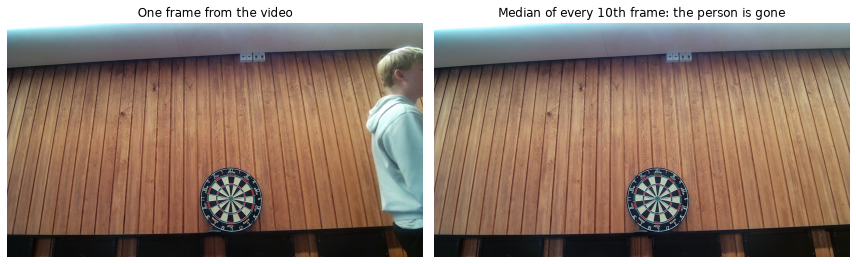

In [28]:
example_video = VIDEO_DIR / "wood_background_yesHuman.mp4"
clean, frames = median_frame(example_video)
show([frames[20], clean], ["One frame from the video", "Median of every 10th frame: the person is gone"])

## **Step 2: Find the bullseye**

The 20 sector boundaries of a dartboard are straight lines that all go through the bullseye.
That gives a simple way to find the centre, similar to the Hough transform:

1. Find edge pixels with Canny edge detection.
2. At each edge pixel, the Sobel gradient points across the edge, so the edge itself runs perpendicular to the gradient.
3. Every edge pixel draws a short line along its edge direction into an empty "vote" image.
4. Lines from all sector edges cross at the bullseye, so that pixel collects the most votes.

Background lines (e.g. wood planks) are mostly parallel, so they do not build up a single strong peak.
This step runs at half resolution, because the centre is only a starting point for the next steps.

In [29]:
def find_centre(image):
    """
    Finds the bullseye: the point where the most edge directions cross.

    Returns the centre (x, y) in full resolution, the edge image and the vote image.
    """
    # Half resolution is enough for a starting point and makes the voting faster.
    # INTER_AREA averages the removed pixels, which avoids aliasing.
    small = cv2.resize(image, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)

    # Blur before differentiating, because derivatives amplify noise
    gray = cv2.GaussianBlur(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), (0, 0), 1.5)

    # Canny gives thin edge lines: gradients above 150 are always edges, gradients
    # between 50 and 150 are only kept if they connect to a strong edge
    edges = cv2.Canny(gray, 50, 150)

    # Sobel gives the brightness slope in x and in y for every pixel
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1)

    # Positions of all edge pixels, and the length of the gradient at each of them.
    # The tiny 1e-6 avoids dividing by zero below.
    ys, xs = np.nonzero(edges)
    magnitude = np.hypot(gx[ys, xs], gy[ys, xs]) + 1e-6

    # The gradient points across the edge. Rotating it by 90 degrees gives the
    # direction along the edge, and dividing by the length gives a vector of length 1.
    dx = -gy[ys, xs] / magnitude
    dy = gx[ys, xs] / magnitude

    # Start with an empty vote image. Each edge pixel will vote along a line that
    # reaches line_length pixels to each side of it.
    votes = np.zeros(gray.shape, np.float32)
    line_length = gray.shape[0] // 8

    # For each distance t, move all edge pixels t steps along their own edge direction
    for t in range(-line_length, line_length + 1):
        px = np.round(xs + t * dx).astype(int)
        py = np.round(ys + t * dy).astype(int)

        # Ignore positions outside the image
        inside = (px >= 0) & (px < gray.shape[1]) & (py >= 0) & (py < gray.shape[0])

        # Add one vote at each position (np.add.at also counts repeated positions)
        np.add.at(votes, (py[inside], px[inside]), 1)

    # Blur the votes so that lines that almost cross still add up, then take the highest peak
    votes = cv2.GaussianBlur(votes, (0, 0), 3)
    _, _, _, peak = cv2.minMaxLoc(votes)

    # We worked at half resolution, so multiply by 2 to get full resolution coordinates
    return (2 * peak[0], 2 * peak[1]), edges, votes

Board centre (x, y): (1032, 810)


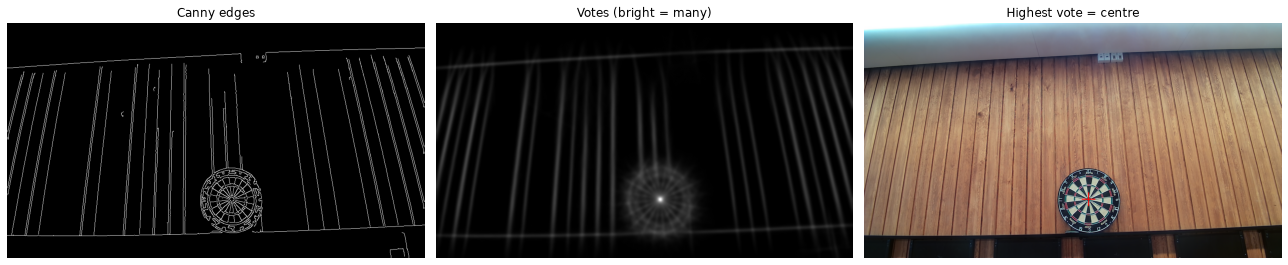

In [30]:
centre, edges, votes = find_centre(clean)
print("Board centre (x, y):", centre)

marked = clean.copy()
cv2.drawMarker(marked, centre, (0, 0, 255), cv2.MARKER_CROSS, 60, 3)

show([edges, votes / votes.max(), marked], ["Canny edges", "Votes (bright = many)", "Highest vote = centre"])

## **Step 3: Find the outer white wire**

First we make the Polar image. We re-sample the image along rays that start at the centre.
In the new image, each row is one direction and each column is the distance from the centre.
Circles around the centre become (almost) vertical lines, and each direction becomes a simple 1D search.

Then we use a top-hat filter. The wire is a thin bright line on black. A morphological opening (erosion followed by dilation) removes bright details thinner than the structuring element.
So image minus opening keeps exactly those thin bright lines.
The structuring element is 11 px long along the radius only. The circular wire crosses the radius, so it is thin in that direction and is kept. The wall gives almost nothing, because it has no thin bright lines.

The black number ring is the darkest wide ring on the board, so it gives a rough board size `r_dark`. The wire must be just outside its middle.
In each direction we take the outermost strong response, since the digits sit further in than the wire.

In [31]:
def polar_image(gray, centre, max_radius):
    """
    Unwraps the image around the centre.

    In the result, row i is direction i * 360 / N_ANGLES degrees and column j is
    the distance j from the centre. Circles around the centre become vertical lines.
    """
    angles = direction_angles()
    radii = np.arange(max_radius, dtype=np.float32)[None, :]

    # For each output pixel, calculate where to read in the input image:
    # x = cx + r * cos(angle), y = cy + r * sin(angle).
    # [:, None] makes this a table with one row per direction and one column per distance.
    map_x = centre[0] + radii * np.cos(angles)[:, None]
    map_y = centre[1] + radii * np.sin(angles)[:, None]

    # remap reads the image at those positions. The positions fall between pixels,
    # so INTER_LINEAR interpolates between the nearest pixels.
    return cv2.remap(gray, map_x.astype(np.float32), map_y.astype(np.float32), cv2.INTER_LINEAR).astype(np.float32)


def thin_bright_lines(polar):
    """
    Keeps only bright lines that are thin along the radius (a top-hat filter).

    The result is bright on the white wire and close to 0 almost everywhere else.
    """
    # Structuring element: 1 row high and 11 columns wide, so 11 px along the radius.
    # Opening removes bright details that are thinner than this.
    opened = cv2.morphologyEx(polar, cv2.MORPH_OPEN, np.ones((1, 11), np.uint8))

    # What the opening removed is exactly the thin bright lines
    return polar - opened


def darkest_ring(polar):
    """
    Finds the rough distance of the outer black number ring from the centre.

    Returns that distance and the brightness profile it was found in.
    """
    # An opening with a square element removes the thin digits and wires
    without_digits = cv2.morphologyEx(polar, cv2.MORPH_OPEN, np.ones((13, 13), np.uint8))

    # Median brightness for each distance (axis=0 combines all directions).
    # The moving average of 15 px smooths out small bumps.
    profile = np.convolve(np.median(without_digits, axis=0), np.ones(15) / 15, mode="same")

    # Darkest distance. The first and last 30 px are skipped, because the moving
    # average is unreliable at the ends and the bullseye is not the ring we want.
    return 30 + int(np.argmin(profile[30:-30])), profile


def polar_to_points(centre, radius_per_angle):
    """Converts one radius per direction back to (x, y) points in the image."""
    angles = direction_angles()
    x = centre[0] + radius_per_angle * np.cos(angles)
    y = centre[1] + radius_per_angle * np.sin(angles)
    return np.column_stack([x, y]).astype(np.float32)


def find_wire_points(top_hat, centre, r_dark):
    """Finds one rough wire position in each direction and returns them as (x, y) points."""
    # The wire lies outside the middle of the black ring, so only search this band
    r_max = min(int(1.5 * r_dark), top_hat.shape[1] - 1)
    band = top_hat[:, r_dark:r_max]

    # Mark positions that are at least half as strong as the strongest one in the same row
    strong = band >= 0.5 * band.max(axis=1, keepdims=True)

    # We want the last marked position, because the digits sit further in than the wire.
    # Flipping each row with [:, ::-1] turns the last one into the first one, and argmax
    # finds the first True. The subtraction converts it back to the original position.
    outermost = band.shape[1] - 1 - np.argmax(strong[:, ::-1], axis=1)

    # Positions in the band start at r_dark, so add it to get the distance from the centre
    return polar_to_points(centre, r_dark + outermost)

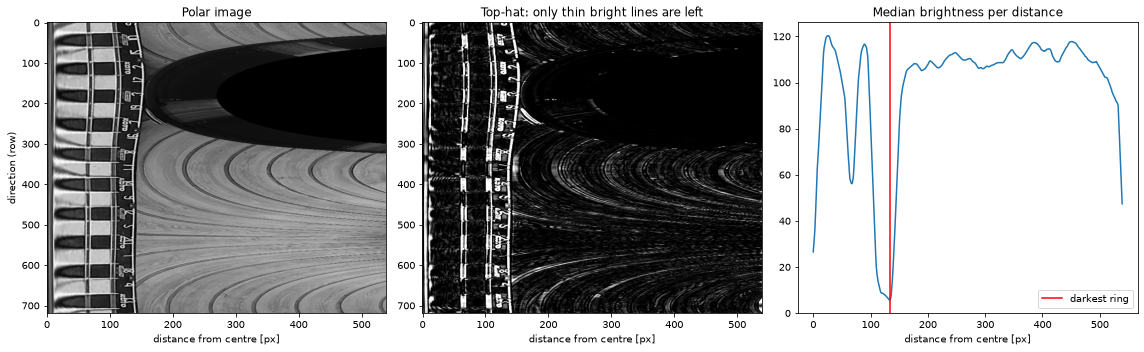

In [32]:
gray = cv2.cvtColor(clean, cv2.COLOR_BGR2GRAY)
polar = polar_image(gray, centre, gray.shape[0] // 2)
top_hat = thin_bright_lines(polar)
r_dark, profile = darkest_ring(polar)
wire_points = find_wire_points(top_hat, centre, r_dark)

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
axs[0].imshow(polar, cmap="gray", aspect="auto")
axs[0].set_title("Polar image")
axs[0].set_xlabel("distance from centre [px]")
axs[0].set_ylabel("direction (row)")
axs[1].imshow(np.clip(top_hat, 0, 60), cmap="gray", aspect="auto")
axs[1].set_title("Top-hat: only thin bright lines are left")
axs[1].set_xlabel("distance from centre [px]")
axs[2].plot(profile)
axs[2].axvline(r_dark, color="r", label="darkest ring")
axs[2].set_title("Median brightness per distance")
axs[2].set_xlabel("distance from centre [px]")
axs[2].legend()
plt.tight_layout()
plt.show()

## **Step 4: Fit the outer ellipse**

Some wire points are wrong, e.g. where the wire is hidden or obscured.
A normal fit (`cv2.fitEllipse`) uses every point, so a few wrong points bend the whole ellipse.

We will use RANSAC for this:

1. Pick 5 random points and fit an ellipse through them.
2. Count how many of all points lie within 2 px of it.
3. Repeat many times and keep the ellipse that most points agree with.
4. Do a final fit on only those points.

Now that we know roughly where the ellipse is, we look only 8 px to each side of it and take the strongest wire response in each direction. Repeating this three times locks the ellipse onto the wire.

In [33]:
def ellipse_error_px(points, ellipse):
    """Returns the rough distance in pixels from each point to the ellipse."""
    (cx, cy), (width, height), angle = ellipse
    t = np.radians(angle)

    # Position of each point relative to the ellipse centre
    dx, dy = points[:, 0] - cx, points[:, 1] - cy

    # Rotate into the ellipse's own axes and divide by the half-axes.
    # A point exactly on the ellipse now has sqrt(u^2 + v^2) = 1.
    u = (dx * np.cos(t) + dy * np.sin(t)) / (width / 2)
    v = (-dx * np.sin(t) + dy * np.cos(t)) / (height / 2)

    # The difference from 1 is the relative error. Multiplying by the
    # average radius of the ellipse converts it to pixels.
    return np.abs(np.sqrt(u**2 + v**2) - 1) * (width + height) / 4


def fit_ellipse_ransac(points, tolerance=2.0, tries=400):
    """
    Fits an ellipse that ignores wrong points (RANSAC).

    Returns the ellipse and the points that agree with it (the inliers).
    """
    # A fixed seed gives the same "random" samples, so every run gives the same result
    rng = np.random.default_rng(0)
    best_ellipse, best_count = None, 0

    for _ in range(tries):
        # 1. Fit an ellipse through 5 random points, the minimum that defines an ellipse
        sample = points[rng.choice(len(points), 5, replace=False)]
        ellipse = cv2.fitEllipse(sample)
        axes = ellipse[1]

        # Skip impossible results (infinite, zero sized or far too large ellipses)
        if not np.all(np.isfinite(axes)) or min(axes) <= 0 or max(axes) > 2000:
            continue

        # 2. Count how many of all the points lie close to this ellipse
        count = np.sum(ellipse_error_px(points, ellipse) < tolerance)

        # 3. Remember the ellipse that most points agree with so far
        if count > best_count:
            best_ellipse, best_count = ellipse, count

    # 4. Final fit through all points that agree with the best ellipse
    inliers = points[ellipse_error_px(points, best_ellipse) < tolerance]
    return cv2.fitEllipse(inliers), inliers

In [34]:
def ellipse_radius_per_angle(ellipse, centre):
    """Returns the distance from `centre` to the ellipse in each of the N_ANGLES directions."""
    (cx, cy), (width, height), angle = ellipse

    # Walk around the ellipse and calculate 4000 points on it
    t = np.linspace(0, 2 * np.pi, 4000, endpoint=False)
    a = np.radians(angle)
    x = cx + width / 2 * np.cos(t) * np.cos(a) - height / 2 * np.sin(t) * np.sin(a)
    y = cy + width / 2 * np.cos(t) * np.sin(a) + height / 2 * np.sin(t) * np.cos(a)

    # Direction and distance of each of those points as seen from `centre`.
    # % (2 * pi) puts the angles between 0 and 2 * pi, like direction_angles().
    point_angles = np.arctan2(y - centre[1], x - centre[0]) % (2 * np.pi)
    point_radii = np.hypot(x - centre[0], y - centre[1])
    order = np.argsort(point_angles)

    # Look up the radius in exactly our N_ANGLES directions. period=2 * pi tells
    # np.interp that the angles wrap around, so 360 degrees is the same as 0 degrees.
    return np.interp(direction_angles(), point_angles[order], point_radii[order], period=2 * np.pi)


def snap_to_wire(ellipse, top_hat, centre, search=8):
    """Moves each point onto the wire by searching close to the current ellipse."""
    expected = ellipse_radius_per_angle(ellipse, centre)
    radii = np.zeros(N_ANGLES)

    for i in range(N_ANGLES):
        # Only look `search` pixels to each side of the ellipse in this direction
        start = max(int(expected[i]) - search, 0)
        segment = top_hat[i, start:int(expected[i]) + search + 1]

        # Light smoothing, so one noisy pixel cannot win
        segment = np.convolve(segment, [0.25, 0.5, 0.25], mode="same")

        # The strongest response is the wire. Add `start` to get the distance from the centre.
        radii[i] = start + np.argmax(segment)

    return polar_to_points(centre, radii)


def find_outer_ellipse(gray, centre):
    """
    Finds the ellipse on the white wire.

    Returns the ellipse, all final wire points and the points that agree with the ellipse.
    """
    # Prepare the polar image, the thin bright lines and the rough board size
    polar = polar_image(gray, centre, gray.shape[0] // 2)
    top_hat = thin_bright_lines(polar)
    r_dark, _ = darkest_ring(polar)

    # First estimate from the rough wire points
    ellipse, _ = fit_ellipse_ransac(find_wire_points(top_hat, centre, r_dark))

    # Each round finds better points close to the ellipse and fits again
    for _ in range(3):
        points = snap_to_wire(ellipse, top_hat, centre)
        ellipse, inliers = fit_ellipse_ransac(points)

    return ellipse, points, inliers

649 of 720 directions agree with the ellipse
Outer ellipse: centre [1033.9  817.4] axes [277.6 290. ] angle 163.1


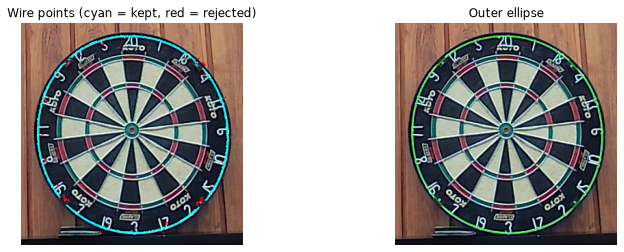

In [35]:
outer_ellipse, outer_points, outer_inliers = find_outer_ellipse(gray, centre)
print(f"{len(outer_inliers)} of {N_ANGLES} directions agree with the ellipse")
print("Outer ellipse: centre", np.round(outer_ellipse[0], 1), "axes", np.round(outer_ellipse[1], 1), "angle", round(outer_ellipse[2], 1))

half_size = int(0.56 * max(outer_ellipse[1]))
result = clean.copy()
for x, y in outer_points:
    cv2.circle(result, (int(x), int(y)), 1, (0, 0, 255), -1)
for x, y in outer_inliers:
    cv2.circle(result, (int(x), int(y)), 1, (255, 255, 0), -1)
points_view = crop_around(result, outer_ellipse[0], half_size)

result = clean.copy()
cv2.ellipse(result, outer_ellipse, (0, 255, 0), 1, cv2.LINE_AA)
ellipse_view = crop_around(result, outer_ellipse[0], half_size)

show([points_view, ellipse_view], ["Wire points (cyan = kept, red = rejected)", "Outer ellipse"])

## **Step 5: Find the inner ellipse**

Here we find points on the outer edge of the double ring.

We sample the image along ellipses with the same shape as the outer ellipse, scaled by a factor from 0.3 to 1.0.
Each column is one scale, and each row is one direction, so the outer ellipse becomes a straight line at 1.0.
The tilt of the camera is removed, and the only thing left to find is where the double ring is.

Between the double ring and the wire the board is almost black, while the double ring is bright. We use the V channel of HSV because red and green rings are both bright in V, even though they look different in gray.
The median of each column ignores digits and logos, since they only appear in some directions. Walking inward from the wire, the first column that gets clearly brighter is the double ring.

Close to that position we find the strongest bright to dark step in each row.

In [36]:
def unroll_board(image, outer_ellipse, bullseye, scales):
    """
    Samples the image along scaled copies of the outer ellipse.

    In the result, each row is one direction around the ellipse and each column is
    one scale, so the outer ellipse becomes a straight line at scale 1.0.
    Also returns map_x and map_y, which say where each result pixel came from in the image.
    """
    (ex, ey), (width, height), angle = outer_ellipse
    a = np.radians(angle)

    # Table of all combinations of scale s and position t around the ellipse
    s, t = np.meshgrid(scales, direction_angles())

    # The ellipse centre moves from the bullseye (s = 0) to the outer ellipse centre (s = 1).
    # Under perspective the shift grows quickly with the size of the circle, hence s**2.
    cx = bullseye[0] + s**2 * (ex - bullseye[0])
    cy = bullseye[1] + s**2 * (ey - bullseye[1])

    # Point on an ellipse: half-axes * (cos t, sin t), rotated by the ellipse angle,
    # scaled by s and moved to the centre (cx, cy)
    map_x = (cx + s * (width / 2 * np.cos(t) * np.cos(a) - height / 2 * np.sin(t) * np.sin(a))).astype(np.float32)
    map_y = (cy + s * (width / 2 * np.cos(t) * np.sin(a) + height / 2 * np.sin(t) * np.cos(a))).astype(np.float32)

    # remap reads the image at all these positions
    return cv2.remap(image, map_x, map_y, cv2.INTER_LINEAR), map_x, map_y

In [37]:
def rough_ring_edge(brightness, scales):
    """
    Finds the rough position of the double ring's outer edge.

    Returns the column of the edge and the brightness threshold that was used.
    """
    def column(scale):
        # Converts a scale (e.g. 0.85) to the matching column number
        return int(np.searchsorted(scales, scale))

    # Typical brightness of the black number ring and of the bright parts of the sectors
    black = np.median(brightness[column(0.85):column(0.95)])
    cream = np.median(brightness[column(0.45):column(0.65)])

    # Threshold just above black. Basing it on these two levels means that it
    # adapts to the exposure of the video.
    threshold = black + 0.15 * (cream - black)

    # Walk inward from the number ring until the brightness passes the threshold
    j = column(0.93)
    while brightness[j] < threshold:
        j -= 1

    return j, threshold


def find_ring_points(value, map_x, map_y, rough_edge, scales):
    """Finds the exact ring edge in each direction and returns them as (x, y) points."""
    # Search width: 0.03 in scale to each side of the rough edge, converted to columns
    half_width = int(0.03 / (scales[1] - scales[0]))
    start, stop = rough_edge - half_width, rough_edge + half_width

    # Blur lightly over 3 columns, then take the Sobel slope along the scale axis.
    # A large negative value means that the image goes from bright to dark going outwards.
    step = cv2.Sobel(cv2.blur(value, (3, 1)), cv2.CV_32F, 1, 0, ksize=5)

    # For each row, the column with the most negative slope is the edge
    columns = start + np.argmin(step[:, start:stop], axis=1)

    # map_x and map_y tell us where each of these positions is in the original image
    rows = np.arange(N_ANGLES)
    return np.column_stack([map_x[rows, columns], map_y[rows, columns]])

In [38]:
def find_inner_edge(image, outer_ellipse, bullseye):
    """
    Finds points on the outer edge of the double ring.

    Returns the points and a dictionary with the intermediate results for the plots.
    """
    # 700 scales from 0.3 to 1.0 of the outer ellipse
    scales = np.linspace(0.3, 1.0, 700)
    unrolled, map_x, map_y = unroll_board(image, outer_ellipse, bullseye, scales)

    # V channel of HSV: V = max(R, G, B), so red and green are both bright
    value = cv2.cvtColor(unrolled, cv2.COLOR_BGR2HSV)[:, :, 2].astype(np.float32)

    # Median of each column ignores digits and logos, because they only appear in
    # some directions. The moving average of 5 columns smooths the curve.
    brightness = np.convolve(np.median(value, axis=0), np.ones(5) / 5, mode="same")

    # First the rough position of the edge, then the exact position in each direction
    rough_edge, threshold = rough_ring_edge(brightness, scales)
    points = find_ring_points(value, map_x, map_y, rough_edge, scales)

    details = dict(unrolled=unrolled, brightness=brightness, scales=scales,
                   rough_edge=scales[rough_edge], threshold=threshold)
    return points, details

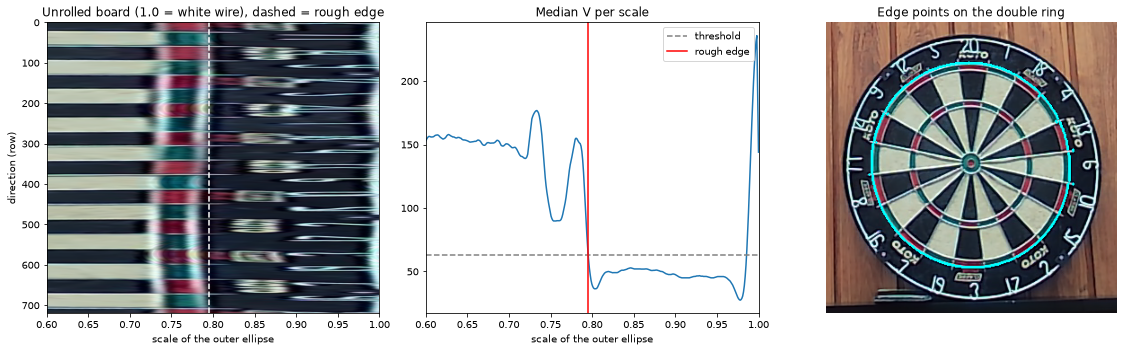

In [39]:
inner_points, details = find_inner_edge(clean, outer_ellipse, centre)

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
axs[0].imshow(cv2.cvtColor(details["unrolled"], cv2.COLOR_BGR2RGB), aspect="auto", extent=[0.3, 1, N_ANGLES, 0])
axs[0].axvline(details["rough_edge"], color="w", linestyle="--")
axs[0].set_xlim(0.6, 1)
axs[0].set_title("Unrolled board (1.0 = white wire), dashed = rough edge")
axs[0].set_xlabel("scale of the outer ellipse")
axs[0].set_ylabel("direction (row)")

axs[1].plot(details["scales"], details["brightness"])
axs[1].axhline(details["threshold"], color="gray", linestyle="--", label="threshold")
axs[1].axvline(details["rough_edge"], color="r", label="rough edge")
axs[1].set_xlim(0.6, 1)
axs[1].set_title("Median V per scale")
axs[1].set_xlabel("scale of the outer ellipse")
axs[1].legend()

result = clean.copy()
for x, y in inner_points:
    cv2.circle(result, (int(x), int(y)), 1, (255, 255, 0), -1)
axs[2].imshow(cv2.cvtColor(crop_around(result, outer_ellipse[0], half_size), cv2.COLOR_BGR2RGB))
axs[2].set_title("Edge points on the double ring")
axs[2].axis("off")
plt.tight_layout()
plt.show()

## **Step 6: Fit the inner ellipse**

Now we use the fact that both circles lie in the same plane. We transform the points so the outer ellipse becomes a unit circle, and in those coordinates the double ring is a circle too.
So we only fit a centre and a radius, and the inner ellipse gets its tilt from the outer ellipse. RANSAC removes the wrong points here as well.

In [40]:
def to_unit_circle(points, ellipse):
    """Moves, rotates and stretches the points so that `ellipse` becomes the unit circle."""
    (ex, ey), (width, height), angle = ellipse
    a = np.radians(angle)

    # Move: the ellipse centre becomes (0, 0)
    dx, dy = points[:, 0] - ex, points[:, 1] - ey

    # Rotate into the ellipse's own axes, and stretch by dividing by the half-axes
    u = (dx * np.cos(a) + dy * np.sin(a)) / (width / 2)
    v = (-dx * np.sin(a) + dy * np.cos(a)) / (height / 2)
    return u, v


def fit_circle(u, v):
    """
    Fits a circle to the points and returns its centre (a, b) and radius.

    The circle equation (u - a)^2 + (v - b)^2 = R^2 can be rewritten as
    u^2 + v^2 = 2*a*u + 2*b*v + c, where c = R^2 - a^2 - b^2.
    This is linear in a, b and c, so least squares solves it directly.
    """
    A = np.column_stack([2 * u, 2 * v, np.ones(len(u))])
    a, b, c = np.linalg.lstsq(A, u**2 + v**2, rcond=None)[0]

    # Get the radius back from c
    return a, b, np.sqrt(c + a**2 + b**2)


def fit_same_shape_ellipse(points, outer_ellipse, tolerance_px=1.5, tries=500):
    """
    Fits the inner ellipse with the same shape and tilt as the outer ellipse.

    Returns the inner ellipse, its size relative to the outer ellipse (the radius in
    unit circle coordinates) and a True/False array of which points agree with it.
    """
    (ex, ey), (width, height), angle = outer_ellipse

    # After this transform the outer ellipse is the unit circle, and the double ring
    # is a circle as well, so we only have to find a centre and a radius
    u, v = to_unit_circle(points, outer_ellipse)

    # The radius of the outer ellipse is now 1, so convert the tolerance from pixels
    tolerance = tolerance_px / ((width + height) / 4)

    rng = np.random.default_rng(0)
    best_circle, best_count = None, 0

    # RANSAC as in step 4, but with 3 points, since 3 points define a circle
    for _ in range(tries):
        i = rng.choice(len(u), 3, replace=False)
        a, b, radius = fit_circle(u[i], v[i])

        # The double ring must be inside the outer ellipse (and the fit must be valid)
        if not np.isfinite(radius) or radius >= 1:
            continue

        # Count the points whose distance to the circle is within the tolerance
        count = np.sum(np.abs(np.hypot(u - a, v - b) - radius) < tolerance)
        if count > best_count:
            best_circle, best_count = (a, b, radius), count

    # Final fit through all points that agree with the best circle
    a, b, radius = best_circle
    inliers = np.abs(np.hypot(u - a, v - b) - radius) < tolerance
    a, b, radius = fit_circle(u[inliers], v[inliers])

    # Back to image coordinates: undo the stretch and rotation for the circle centre
    t = np.radians(angle)
    cx = ex + a * width / 2 * np.cos(t) - b * height / 2 * np.sin(t)
    cy = ey + a * width / 2 * np.sin(t) + b * height / 2 * np.cos(t)

    # Same angle and same shape as the outer ellipse, scaled by `radius`
    return ((cx, cy), (radius * width, radius * height), angle), radius, inliers

706 of 720 directions agree with the ellipse
Inner ellipse is 0.7901 x the outer ellipse


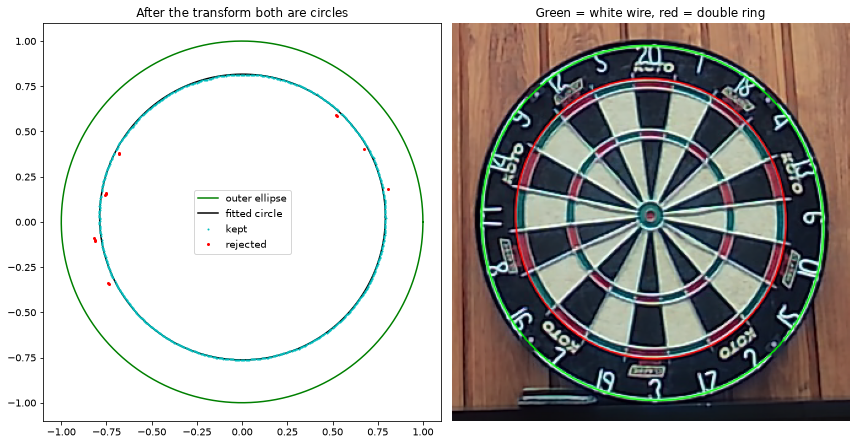

In [41]:
inner_ellipse, ratio, inner_inliers = fit_same_shape_ellipse(inner_points, outer_ellipse)
print(f"{inner_inliers.sum()} of {N_ANGLES} directions agree with the ellipse")
print(f"Inner ellipse is {ratio:.4f} x the outer ellipse")

u, v = to_unit_circle(inner_points, outer_ellipse)
a, b, radius = fit_circle(u[inner_inliers], v[inner_inliers])
t = np.linspace(0, 2 * np.pi, 360)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].plot(np.cos(t), np.sin(t), color="g", label="outer ellipse")
axs[0].plot(a + radius * np.cos(t), b + radius * np.sin(t), color="k", label="fitted circle")
axs[0].plot(u[inner_inliers], v[inner_inliers], "c.", markersize=2, label="kept")
axs[0].plot(u[~inner_inliers], v[~inner_inliers], "r.", markersize=4, label="rejected")
axs[0].set_aspect("equal")
axs[0].set_title("After the transform both are circles")
axs[0].legend(loc="center")

result = clean.copy()
cv2.ellipse(result, outer_ellipse, (0, 255, 0), 1, cv2.LINE_AA)
cv2.ellipse(result, inner_ellipse, (0, 0, 255), 1, cv2.LINE_AA)
axs[1].imshow(cv2.cvtColor(crop_around(result, outer_ellipse[0], half_size), cv2.COLOR_BGR2RGB))
axs[1].set_title("Green = white wire, red = double ring")
axs[1].axis("off")
plt.tight_layout()
plt.show()

## **Step 7: Check the results**

`detect_board` runs steps 2–6 on one image, and `calibrate_from_video` adds the median frame from step 1.

In [42]:
def detect_board(image):
    """
    Runs steps 2-6 on one image.

    Returns a dictionary with the bullseye, both ellipses, the inner/outer size ratio
    and how many of the directions agree with each ellipse.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    bullseye, _, _ = find_centre(image)                                    # step 2
    outer_ellipse, _, outer_inliers = find_outer_ellipse(gray, bullseye)   # steps 3 and 4
    inner_points, _ = find_inner_edge(image, outer_ellipse, bullseye)      # step 5
    inner_ellipse, ratio, inner_inliers = fit_same_shape_ellipse(inner_points, outer_ellipse)   # step 6

    return dict(
        bullseye=bullseye, outer=outer_ellipse, inner=inner_ellipse, ratio=ratio,
        outer_agreement=len(outer_inliers) / N_ANGLES,
        inner_agreement=inner_inliers.sum() / N_ANGLES,
    )


def draw_board(image, board, thickness=1):
    """Returns a copy of the image with the outer ellipse in green and the inner ellipse in red."""
    output = image.copy()   # copy, so the original image is not drawn on
    cv2.ellipse(output, board["outer"], (0, 255, 0), thickness, cv2.LINE_AA)
    cv2.ellipse(output, board["inner"], (0, 0, 255), thickness, cv2.LINE_AA)
    return output


def calibrate_from_video(video_path):
    """Runs the full detector on one video: step 1 first, then steps 2-6 on the clean image."""
    clean, frames = median_frame(video_path)

    # Only the detection is timed, not reading the video
    start = time.perf_counter()
    board = detect_board(clean)
    board["seconds"] = time.perf_counter() - start

    board["image"] = clean   # kept so the result can be drawn on it later
    return board

In [43]:
boards = {video.stem: calibrate_from_video(video) for video in videos}

print(f"{'video':32s} {'outer agree':>12s} {'inner agree':>12s} {'inner/outer':>12s} {'axis ratio':>11s} {'seconds':>8s}")
for name, b in boards.items():
    axes = b["outer"][1]
    print(f"{name:32s} {b['outer_agreement']:12.0%} {b['inner_agreement']:12.0%} {b['ratio']:12.4f} "
          f"{min(axes) / max(axes):11.3f} {b['seconds']:8.1f}")

video                             outer agree  inner agree  inner/outer  axis ratio  seconds
black_background_LightChange              91%          98%       0.7870       0.977      0.2
black_background_noHuman                  91%          98%       0.7870       0.981      0.2
black_background_yesHuman                 92%          98%       0.7869       0.978      0.2
white_background_LightChange              78%          96%       0.7854       0.938      0.2
white_background_noHuman                  83%          96%       0.7861       0.937      0.2
white_background_yesHuman                 83%          97%       0.7860       0.937      0.2
wood_background_Angle                     89%          97%       0.7908       0.860      0.2
wood_background_LightChange               89%          95%       0.7895       0.958      0.4
wood_background_noHuman                   89%          98%       0.7903       0.958      0.3
wood_background_yesHuman                  90%          98%       0.790

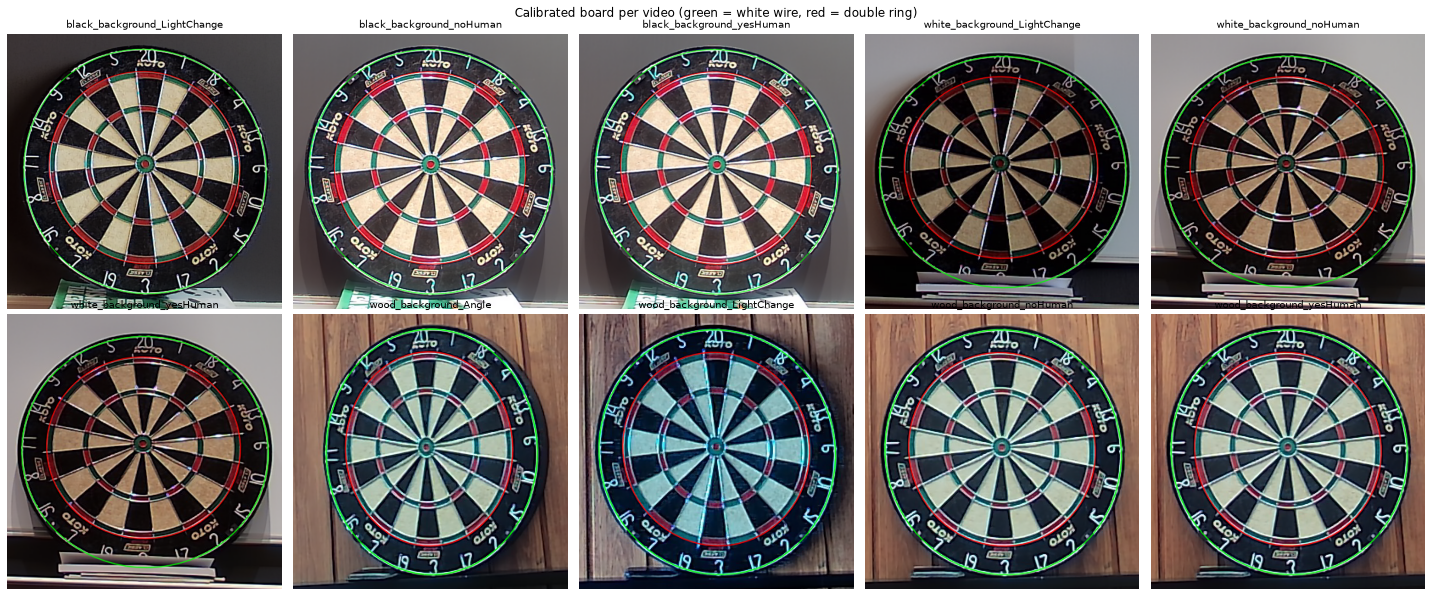

In [44]:
fig, axs = plt.subplots(2, 5, figsize=(20, 8.4))

for ax, (name, b) in zip(axs.ravel(), boards.items()):
    half_size = int(0.56 * max(b["outer"][1]))
    output = crop_around(draw_board(b["image"], b), b["outer"][0], half_size)
    ax.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    ax.set_title(name, fontsize=10)
    ax.axis("off")

plt.suptitle("Calibrated board per video (green = white wire, red = double ring)")
plt.tight_layout()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURE_DIR / "board_detection_all_videos.png", dpi=150)
plt.show()

### Zoom on the hardest case

The angled video at 3x zoom, on the left and right side of the board.

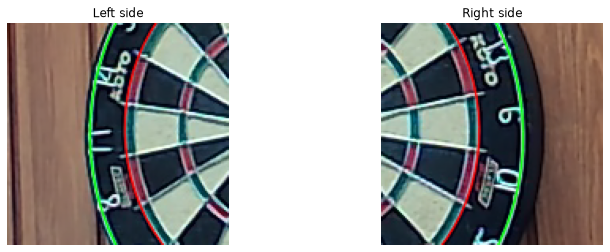

In [45]:
b = boards["wood_background_Angle"]
drawn = draw_board(b["image"], b)
(cx, cy), (width, height), _ = b["outer"]

left = crop_around(drawn, (cx - 0.42 * width, cy), 70)
right = crop_around(drawn, (cx + 0.42 * width, cy), 70)
zoom = lambda image: cv2.resize(image, None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST)
show([zoom(left), zoom(right)], ["Left side", "Right side"])

### Watch the video with the rings

Plays one video inside the notebook, with the rings from the calibration drawn on every frame.
The rings do not move, because the board is only detected once. They should stay on the board while the person walks past.

Change `VIDEO_TO_PLAY` to see another video, and run the cell again to replay it. Press the stop button of the cell to stop early.

In [46]:
def play_video(video_path, board, width=960, frame_step=2):
    """
    Plays a video in the notebook output with the rings drawn on top.

    Only every `frame_step`-th frame is shown, so the notebook can keep up with the video.
    """
    cap = cv2.VideoCapture(str(video_path))
    seconds_per_frame = frame_step / cap.get(cv2.CAP_PROP_FPS)
    scale = width / cap.get(cv2.CAP_PROP_FRAME_WIDTH)

    # One output area that we keep replacing with the newest frame
    player = display(display_id=True)
    index = 0

    try:
        while True:
            ok, frame = cap.read()
            if not ok:   # end of the video
                break

            if index % frame_step == 0:
                start = time.perf_counter()

                # Thicker rings, because shrinking the frame makes thin lines fade
                output = draw_board(frame, board, thickness=2)
                output = cv2.resize(output, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

                # A notebook shows image files, so compress the frame to JPEG first
                _, jpeg = cv2.imencode(".jpg", output)
                player.update(Image(data=jpeg.tobytes()))

                # Wait for the rest of this frame's time, so the video plays at normal speed
                time.sleep(max(0, seconds_per_frame - (time.perf_counter() - start)))

            index += 1

    except KeyboardInterrupt:
        pass   # the stop button was pressed

    finally:
        cap.release()

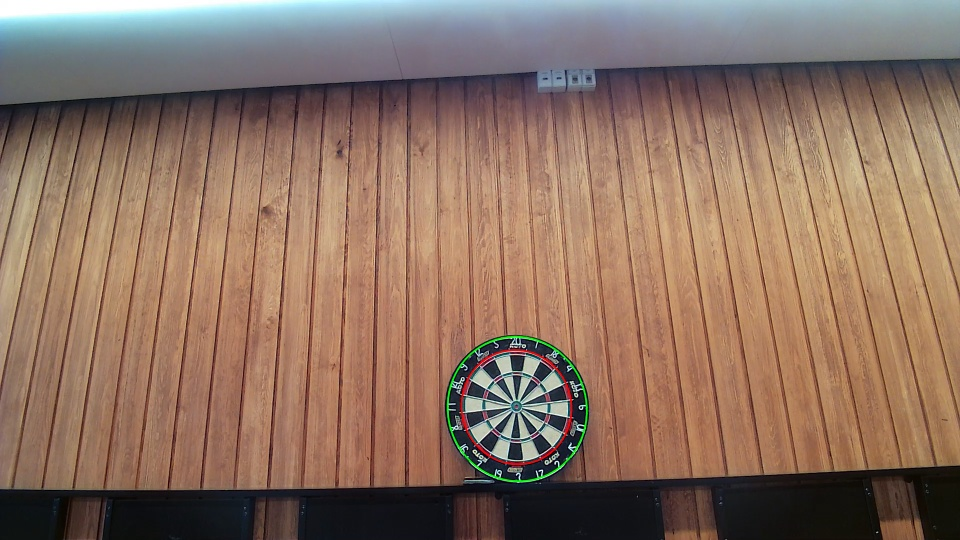

In [47]:
VIDEO_TO_PLAY = "wood_background_yesHuman"

play_video(VIDEO_DIR / f"{VIDEO_TO_PLAY}.mp4", boards[VIDEO_TO_PLAY])